# ChestScan AI — CNN pour classer des radiographies (NORMAL vs PNEUMONIA)

**Étapes :** charger les données → explorer → vérifier les images → préparer (resize, RGB, labels, split, normalisation) → visualiser → déséquilibre → construire le CNN.

**Dataset :** Kaggle *Chest X-Ray Images (Pneumonia)* — `paultimothymooney/chest-xray-pneumonia`

## 1. Imports

In [1]:
import os, time, json
import kagglehub
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score,confusion_matrix,ConfusionMatrixDisplay,
    classification_report
)

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

2026-10-22 17:01:49.340538: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792688509.361550   17771 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792688509.368005   17771 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792688509.385208   17771 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792688509.385230   17771 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792688509.385232   17771 computation_placer.cc:177] computation placer alr

## 2. Chargement et prétraitement du dataset

### 2.1 Charger le dataset

In [2]:
DATA_DIR = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
print("Dossier trouvé :", DATA_DIR.exists())

Dossier trouvé : True


### 2.2 Explorer la structure des dossiers et identifier les classes

In [3]:
for split in DATA_DIR.iterdir():
    if split.is_dir():                     
        for classe in split.iterdir():
            if classe.is_dir():
                print(split.name, "->", classe.name)

chest_xray -> __MACOSX
chest_xray -> chest_xray
chest_xray -> test
chest_xray -> train
chest_xray -> val


### 2.3 Nombre d'images par classe et répartition NORMAL / PNEUMONIA

In [4]:
SPLITS = ["train", "val", "test"]
CLASSES = ["NORMAL", "PNEUMONIA"]
EXTENSIONS = {".jpg", ".jpeg", ".png"}

def compter_images(root, splits, classes):
    stats = {}
    for split in splits:
        stats[split] = {}
        for classe in classes:
            dossier = root / split / classe
            if dossier.is_dir():
                stats[split][classe] = sum(
                    1 for f in dossier.iterdir()
                    if f.is_file()
                    and f.suffix.lower() in EXTENSIONS
                    and not f.name.startswith("._")     
                )
            else:
                print(f"Dossier introuvable : {dossier}")
                stats[split][classe] = 0
    return stats

def _has_images(folder: Path) -> bool:
    return folder.is_dir() and any(
        f.is_file() and f.suffix.lower() in EXTENSIONS and not f.name.startswith("._")
        for f in folder.iterdir()
    )

def _is_dataset_root(p: Path) -> bool:
    tr = p / "train"
    if not tr.is_dir():
        return False
    return all(_has_images(tr / c) for c in CLASSES)

def find_root(base: Path) -> Path:
    if _is_dataset_root(base):
        return base
    for depth in range(1, 4):
        for p in base.glob("/".join(["*"] * depth) + "/train"):
            cand = p.parent
            if p.name == "train" and _is_dataset_root(cand):
                return cand
    raise FileNotFoundError(f"No dataset root found under {base}")

ROOT = find_root(DATA_DIR)
print("ROOT:", ROOT)

df_stats = pd.DataFrame(compter_images(ROOT, SPLITS, CLASSES)).T
df_stats["Total"] = df_stats[CLASSES].sum(axis=1)
df_stats["% PNEUMONIA"] = (df_stats["PNEUMONIA"] / df_stats["Total"] * 100).round(1)
print(df_stats)

ROOT: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray
       NORMAL  PNEUMONIA  Total  % PNEUMONIA
train    1341       3875   5216         74.3
val         8          8     16         50.0
test      234        390    624         62.5


### 2.4 Problèmes liés aux images (fichiers corrompus, modes, tailles)

In [5]:
from pathlib import Path
from collections import Counter
from PIL import Image

def rapport(dossier: Path):
    stats = {"total": 0, "ok": 0, "corrompus": [], "modes": Counter(), "tailles": Counter()}
    for f in dossier.rglob("*"):
        if not f.is_file():
            continue
        if f.suffix.lower() not in EXTENSIONS:
            continue
        if f.name.startswith("._"):         
            continue
        stats["total"] += 1
        try:
            with Image.open(f) as img:
                img.load()                   
                stats["modes"][img.mode] += 1
                stats["tailles"][img.size] += 1
                stats["ok"] += 1
        except Exception as e:
            stats["corrompus"].append((f, f"{type(e).__name__}: {e}"))
    return stats

for split in SPLITS:
    r = rapport(ROOT / split)               
    print(f"--- {split} ---")
    print("Total     :", r["total"])
    print("OK        :", r["ok"])
    print("Corrompus :", len(r["corrompus"]))
    print("Modes     :", dict(r["modes"]))
    print("Nb tailles différentes :", len(r["tailles"]))
    for f, err in r["corrompus"]:
        print("  Fichier à supprimer :", f, err)

--- train ---
Total     : 5216
OK        : 5216
Corrompus : 0
Modes     : {'L': 4933, 'RGB': 283}
Nb tailles différentes : 4366
--- val ---
Total     : 16
OK        : 16
Corrompus : 0
Modes     : {'L': 16}
Nb tailles différentes : 16
--- test ---
Total     : 624
OK        : 624
Corrompus : 0
Modes     : {'L': 624}
Nb tailles différentes : 598


### 2.5 Charger les images : resize 180×180, RGB, labels (noms des dossiers) et split train / validation / test

- `image_size=(180, 180)` : redimensionne toutes les images.
- `color_mode="rgb"` : convertit les images en 3 canaux (même celles en niveaux de gris).
- Les labels viennent des noms de dossiers (ordre alphabétique) : NORMAL = 0, PNEUMONIA = 1.
- Le dossier `val/` fourni contient seulement 16 images : trop peu pour valider. On prend donc **20 % de `train/`** comme validation.
- Le dossier `test/` n'est **jamais** utilisé pour l'entraînement : il reste indépendant.

In [6]:
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

# 80 % de train/ pour l'entraînement
train_ds = tf.keras.utils.image_dataset_from_directory(
    ROOT / "train",                     
    validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, color_mode="rgb",
    batch_size=BATCH_SIZE, label_mode="binary",
)

# 20 % de train/ pour la validation
val_ds = tf.keras.utils.image_dataset_from_directory(
    ROOT / "train",                    
    validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, color_mode="rgb",
    batch_size=BATCH_SIZE, label_mode="binary",
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    ROOT / "test",                  
    image_size=IMG_SIZE, color_mode="rgb",
    batch_size=BATCH_SIZE, label_mode="binary",
    shuffle=False,
)

class_names = train_ds.class_names
print("Classes :", class_names)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.


I0000 00:00:1792688535.049848   17771 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10261 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:09:00.0, compute capability: 8.6


Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
Classes : ['NORMAL', 'PNEUMONIA']


### 2.6 Vérifier le format attendu par le CNN (3 canaux)

In [7]:
for images, labels in train_ds.take(1): #recuperer une seule batch du dataset
    print("Forme des images :", images.shape)      # (batch, 180, 180, 3)
    print("Nombre de canaux :", images.shape[-1])  
    print("Type             :", images.dtype)
    print("Plage de pixels  :", images.numpy().min(), "->", images.numpy().max())

Forme des images : (32, 180, 180, 3)
Nombre de canaux : 3
Type             : <dtype: 'float32'>
Plage de pixels  : 0.0 -> 255.0


2026-10-22 17:02:17.031942: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


### 2.7 Associer les labels aux images (noms des dossiers)

In [8]:
for i, nom in enumerate(class_names):
    print(f"{nom:10s} -> label {i}")

NORMAL     -> label 0
PNEUMONIA  -> label 1


### 2.8 Vérifier le split train / validation / test

In [9]:
def compter(ds):
    return sum(len(labels) for _, labels in ds)

print("Train :", compter(train_ds))
print("Val   :", compter(val_ds))
print("Test  :", compter(test_ds))

2026-10-22 17:02:20.523850: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Train : 4173
Val   : 1043
Test  : 624


2026-10-22 17:02:22.104697: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


### 2.10 Visualiser des images de chaque classe

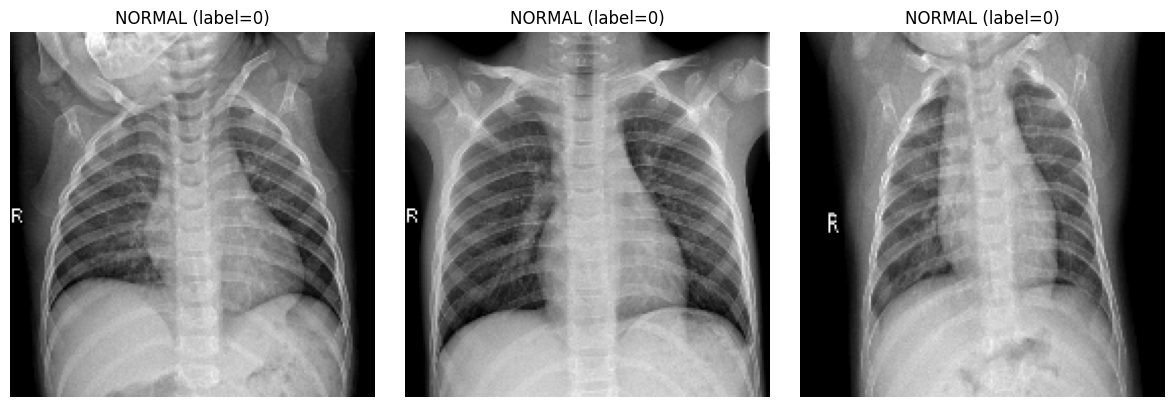

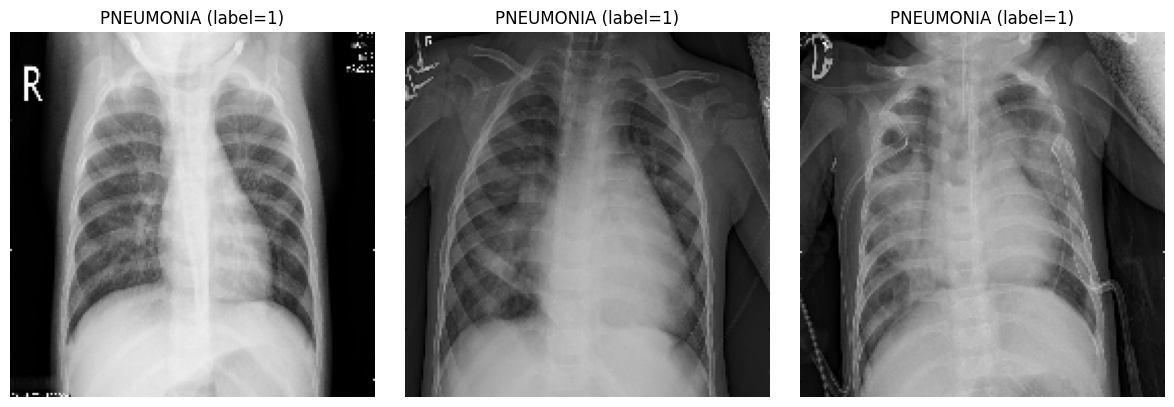

In [10]:
def afficher_echantillons(ds, class_names, n=3):
    for images, labels in ds.take(1):
        images = images.numpy().astype("uint8")
        labels = labels.numpy().flatten()

        for classe_idx, classe_nom in enumerate(class_names):
            idxs = np.where(labels == classe_idx)[0][:n]
            if len(idxs) == 0:
                print(f"Aucune image {classe_nom} dans ce lot")
                continue

            fig, axes = plt.subplots(1, len(idxs), figsize=(4 * len(idxs), 4))
            axes = np.atleast_1d(axes)
            for ax, idx in zip(axes, idxs):
                ax.imshow(images[idx])
                ax.set_title(f"{classe_nom} (label={labels[idx]:.0f})")
                ax.axis("off")
            plt.tight_layout()
            plt.show()

afficher_echantillons(train_ds, class_names, n=3)

### 2.11 Distribution des classes

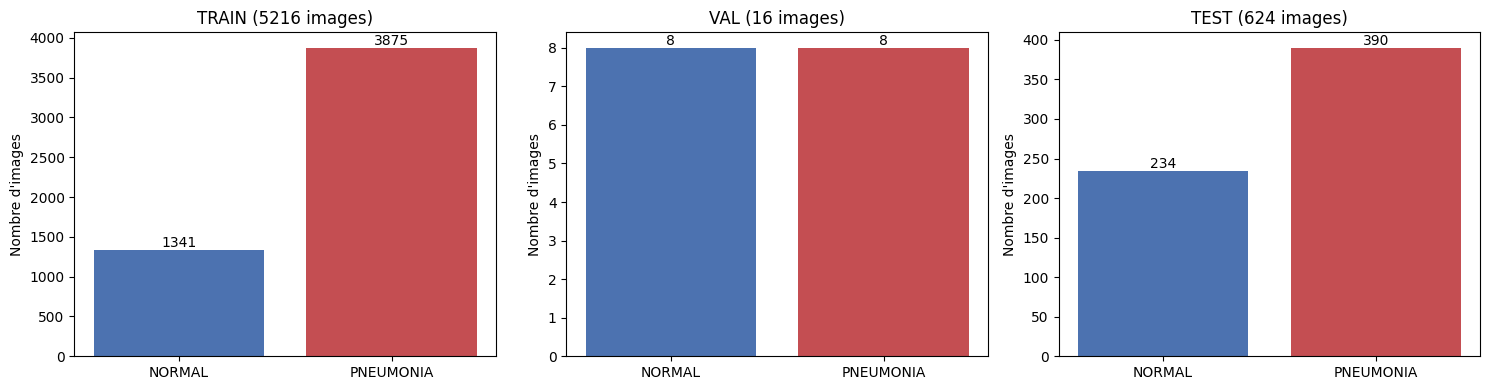

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, split in zip(axes, SPLITS):
    valeurs = [df_stats.loc[split, c] for c in CLASSES]
    bars = ax.bar(CLASSES, valeurs, color=["#4C72B0", "#C44E52"])
    ax.set_title(f"{split.upper()} ({sum(valeurs)} images)")
    ax.set_ylabel("Nombre d'images")
    for bar, v in zip(bars, valeurs):
        ax.text(bar.get_x() + bar.get_width() / 2, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

### 2.12 Déséquilibre des classes et stratégie

Il y a beaucoup plus d'images PNEUMONIA que NORMAL. Sans correction, le modèle peut prédire « PNEUMONIA » presque tout le temps.

**Stratégie :** `class_weight`. La classe rare (NORMAL) reçoit un poids plus grand pendant l'entraînement.

In [12]:
n_normal = df_stats.loc["train", "NORMAL"]
n_pneumo = df_stats.loc["train", "PNEUMONIA"]
ratio = n_pneumo / n_normal

class_weight_balanced = {
    0: (n_normal + n_pneumo) / (2 * n_normal),
    1: (n_normal + n_pneumo) / (2 * n_pneumo),
}

beta = 1.5 
class_weight = {
    0: class_weight_balanced[0] * beta,
    1: class_weight_balanced[1],
}

print(f"Ratio PNEUMONIA/NORMAL : {ratio:.2f}")
print(f"Poids standard         : {class_weight_balanced}")
print(f"Poids retenus (β={beta}) : {class_weight}")

Ratio PNEUMONIA/NORMAL : 2.89
Poids standard         : {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}
Poids retenus (β=1.5) : {0: np.float64(2.9172259507829974), 1: np.float64(0.6730322580645162)}


## 3. Conception du modèle CNN

Un CNN (réseau de neurones convolutif) apprend automatiquement des motifs visuels (bords, formes, textures) :

- `Conv2D` : détecte des motifs dans l'image.
- `MaxPooling2D` : réduit la taille de l'image en gardant l'essentiel.
- `Flatten` : met les résultats à plat (un seul vecteur).
- `Dense` : prend la décision finale.
- `Dropout` : éteint des neurones au hasard pendant l'entraînement pour limiter le surapprentissage.
- Sortie `sigmoid` : donne une probabilité entre 0 et 1 (proche de 1 = PNEUMONIA).

### 3.1 Hyperparamètres

In [13]:
EPOCHS = 10          # nombre de passages sur les données d'entraînement
LEARNING_RATE = 1e-3 # vitesse d'apprentissage de l'optimiseur Adam

### 3.2 Augmentation des images

Ces transformations aléatoires créent des variantes légères des images, seulement pendant l'entraînement.
Pas de flip horizontal : sur une radio, le côté du cœur est une information médicale.

In [14]:
augmentation = keras.Sequential([
    layers.RandomRotation(0.05),   # petite rotation
    layers.RandomZoom(0.1),        # petit zoom
    layers.RandomContrast(0.1),    # petite variation de contraste
], name="augmentation")

### 3.3 Architecture, compilation et résumé

In [15]:
model = models.Sequential([
    layers.Input(shape=(180, 180, 3)),        # images 180x180, 3 canaux

    augmentation,                             # actif seulement à l'entraînement
    layers.Rescaling(1./255),                 # normalisation [0, 1] (une seule fois)

    # 4 blocs : Conv2D (extrait des motifs) + MaxPooling2D (réduit la taille)
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Flatten(),                         # met les caractéristiques à plat
    layers.Dense(128, activation="relu"),     # couche de classification
    layers.Dropout(0.5),                      # limite le surapprentissage
    layers.Dense(1, activation="sigmoid"),    # sortie binaire (probabilité)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",               # perte adaptée à 2 classes
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 22, 22, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 11, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 15488)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,982,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,223,553 (8.48 MB)

 Trainable params: 2,223,553 (8.48 MB)

 Non-trainable params: 0 (0.00 B)

### 3.4 Entraînement (vérifier que le modèle apprend)

`class_weight` compense le déséquilibre. `EarlyStopping` arrête l'entraînement quand la validation ne s'améliore plus.

In [16]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_auc", mode="max", patience=5, restore_best_weights=True
)

t0 = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=[early_stop],
)
T_SCRATCH = time.time() - t0


Epoch 1/10


I0000 00:00:1792688551.462129   18223 cuda_dnn.cc:529] Loaded cuDNN version 90300


131/131 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - accuracy: 0.4326 - auc: 0.6647 - loss: 0.7989 - val_accuracy: 0.8840 - val_auc: 0.9672 - val_loss: 0.3224
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 59ms/step - accuracy: 0.8597 - auc: 0.9469 - loss: 0.3686 - val_accuracy: 0.9262 - val_auc: 0.9891 - val_loss: 0.2090
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 59ms/step - accuracy: 0.9027 - auc: 0.9702 - loss: 0.2727 - val_accuracy: 0.8485 - val_auc: 0.9876 - val_loss: 0.3955
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.9289 - auc: 0.9828 - loss: 0.2000 - val_accuracy: 0.9214 - val_auc: 0.9927 - val_loss: 0.2095
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.9317 - auc: 0.9868 - loss: 0.1715 - val_accuracy: 0.9559 - val_auc: 0.9927 - val_loss: 0.1181
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.9332 - auc: 0.9899 - loss: 0.1591 - val_accuracy: 0.9281 - val_auc: 0.9915 - val_loss: 0.2228
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 5

### 4. Évaluation du CNN

l'accuracy, la precision, le recall, le F1-score et le ROC-AUC.

In [17]:
y_proba = model.predict(test_ds, verbose=1).ravel()

y_true = np.concatenate([y.numpy() for _, y in test_ds]).astype(int).ravel()

y_pred = (y_proba >= 0.5).astype(int)

acc = accuracy_score(y_true,y_pred)
pre = precision_score(y_true,y_pred)
rec = recall_score(y_true,y_pred)
f1 = f1_score(y_true,y_pred)
acc=accuracy_score(y_true,y_pred)
auc = roc_auc_score(y_true,y_proba)

print(f"ROC-AUC : {auc:.4f}")
print(f"Accuracy          : {acc:.4f}")
print(f"Precision         : {pre:.4f}")
print(f"Recall (Sensib.)  : {rec:.4f}")
print(f"F1-score          : {f1:.4f}")


20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step 
ROC-AUC : 0.9584
Accuracy          : 0.8317
Precision         : 0.7926
Recall (Sensib.)  : 0.9897
F1-score          : 0.8803


In [18]:
cm = confusion_matrix(y_true,y_pred)
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

[[133 101]
 [  4 386]]
TN=133  FP=101  FN=4  TP=386


In [19]:
class_report = classification_report(y_true, y_pred, target_names=class_names)

print(class_report)

              precision    recall  f1-score   support

      NORMAL       0.97      0.57      0.72       234
   PNEUMONIA       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.78      0.80       624
weighted avg       0.86      0.83      0.82       624



### 5. Transfer Learning avec MobileNetV2

MobileNetV2 a été préentraîné sur ImageNet (1,4M images, 1000 classes).
Il a appris des features visuelles génériques (bords, textures, formes)
qui sont réutilisables pour d'autres tâches.

Principe en 3 points :
1. On charge le backbone préentraîné sans sa couche de classification.
2. On le gèle pour protéger les features ImageNet.
3. On ajoute une nouvelle tête de classification (NORMAL / PNEUMONIA)
   et on n'entraîne que cette tête.

In [20]:
IMG_SIZE_TL = (224, 224)

base_model = MobileNetV2(
    input_shape=IMG_SIZE_TL + (3,),
    include_top=False, #supprimer le HEAD original
    weights="imagenet"
)
print("Base model chargé :", base_model.name)
print("Sortie du backbone :", base_model.output_shape)

Base model chargé : mobilenetv2_1.00_224
Sortie du backbone : (None, 7, 7, 1280)


In [21]:
train_ds_tl = tf.keras.utils.image_dataset_from_directory(
    ROOT / "train",
    validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE_TL, color_mode="rgb",
    batch_size=BATCH_SIZE, label_mode="binary",
).map(lambda x, y: (preprocess_input(x), y)).prefetch(AUTOTUNE)

val_ds_tl = tf.keras.utils.image_dataset_from_directory(
    ROOT / "train",
    validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE_TL, color_mode="rgb",
    batch_size=BATCH_SIZE, label_mode="binary",
).map(lambda x, y: (preprocess_input(x), y)).prefetch(AUTOTUNE)

test_ds_tl = tf.keras.utils.image_dataset_from_directory(
    ROOT / "test",
    image_size=IMG_SIZE_TL, color_mode="rgb",
    batch_size=BATCH_SIZE, label_mode="binary", shuffle=False,
).map(lambda x, y: (preprocess_input(x), y)).prefetch(AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.


In [22]:
augmentation_tl = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation_tl")

base_model.trainable = False

inputs = layers.Input(shape=IMG_SIZE_TL + (3,))
x = augmentation_tl(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model_tl = keras.Model(inputs, outputs, name="mobilenetv2_pneumonia")

In [23]:
model_tl.summary()

trainable_count = sum([tf.size(w).numpy() for w in model_tl.trainable_weights])
non_trainable_count = sum([tf.size(w).numpy() for w in model_tl.non_trainable_weights])
print(f"Paramètres entraînables     : {trainable_count:,}")
print(f"Paramètres non entraînables : {non_trainable_count:,}")

Model: "mobilenetv2_pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_tl (Sequential)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Paramètres entraînables     : 164,097
Paramètres non entraînables : 2,257,984


In [24]:
model_tl.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

early_stop_tl = keras.callbacks.EarlyStopping(
    monitor="val_auc", mode="max", patience=4, restore_best_weights=True
)

t0 = time.time()
history_tl = model_tl.fit(
    train_ds_tl,
    validation_data=val_ds_tl,
    epochs=10,
    class_weight=class_weight,
    callbacks=[early_stop_tl],
)
T_TL = time.time() - t0


Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 18s 94ms/step - accuracy: 0.8232 - auc: 0.9273 - loss: 0.4067 - val_accuracy: 0.8639 - val_auc: 0.9671 - val_loss: 0.2947
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - accuracy: 0.9326 - auc: 0.9822 - loss: 0.2055 - val_accuracy: 0.9252 - val_auc: 0.9689 - val_loss: 0.1944
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - accuracy: 0.9264 - auc: 0.9822 - loss: 0.2004 - val_accuracy: 0.9300 - val_auc: 0.9703 - val_loss: 0.1859
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 11s 84ms/step - accuracy: 0.9219 - auc: 0.9821 - loss: 0.2023 - val_accuracy: 0.9262 - val_auc: 0.9712 - val_loss: 0.1877
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - accuracy: 0.9340 - auc: 0.9871 - loss: 0.1734 - val_accuracy: 0.8639 - val_auc: 0.9666 - val_loss: 0.3356
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - accuracy: 0.9373 - auc: 0.9847 - loss: 0.1831 - val_accuracy: 0.9300 - val_auc: 0.9684 - val_loss: 0.1979
Epoch 7/10
131/131 ━━━━━━━━━

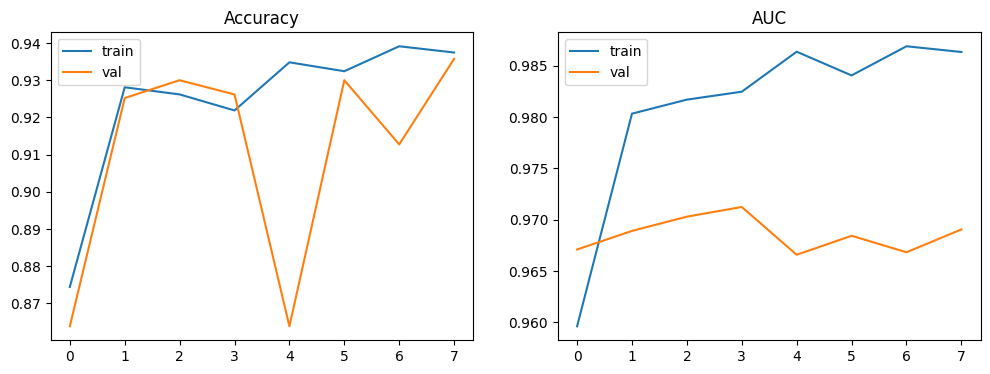

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_tl.history["accuracy"], label="train")
axes[0].plot(history_tl.history["val_accuracy"], label="val")
axes[0].set_title("Accuracy")
axes[0].legend()
axes[1].plot(history_tl.history["auc"], label="train")
axes[1].plot(history_tl.history["val_auc"], label="val")
axes[1].set_title("AUC")
axes[1].legend()
plt.show()

In [26]:
y_proba_tl = model_tl.predict(test_ds_tl, verbose=1).ravel()
y_pred_tl = (y_proba_tl >= 0.5).astype(int)

print(f"ROC-AUC : {roc_auc_score(y_true, y_proba_tl):.4f}")
print(f"Accuracy          : {accuracy_score(y_true, y_pred_tl):.4f}")
print(f"Precision         : {precision_score(y_true, y_pred_tl):.4f}")
print(f"Recall (Sensib.)  : {recall_score(y_true, y_pred_tl):.4f}")
print(f"F1-score          : {f1_score(y_true, y_pred_tl):.4f}")
print()
print(confusion_matrix(y_true, y_pred_tl))
print(classification_report(y_true, y_pred_tl, target_names=class_names))

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step
ROC-AUC : 0.9176
Accuracy          : 0.7548
Precision         : 0.7240
Recall (Sensib.)  : 0.9821
F1-score          : 0.8335

[[ 88 146]
 [  7 383]]
              precision    recall  f1-score   support

      NORMAL       0.93      0.38      0.53       234
   PNEUMONIA       0.72      0.98      0.83       390

    accuracy                           0.75       624
   macro avg       0.83      0.68      0.68       624
weighted avg       0.80      0.75      0.72       624



### 5.1 Baseline Transfer Learning (avant fine-tuning)

In [27]:
def evaluer(m, ds, nom, seuil=0.5):
    y_proba_m = m.predict(ds, verbose=0).ravel()
    y_pred_m = (y_proba_m >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred_m).ravel()
    return {
        "modèle": nom,
        "accuracy": accuracy_score(y_true, y_pred_m),
        "precision": precision_score(y_true, y_pred_m),
        "recall": recall_score(y_true, y_pred_m),
        "f1": f1_score(y_true, y_pred_m),
        "roc_auc": roc_auc_score(y_true, y_proba_m),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

res_before = evaluer(model_tl, test_ds_tl, "TL (backbone gelé)")
print(pd.Series(res_before))

modèle       TL (backbone gelé)
accuracy               0.754808
precision              0.724008
recall                 0.982051
f1                     0.833515
roc_auc                0.917565
TN                           88
FP                          146
FN                            7
TP                          383
dtype: object


In [28]:
# Sauvegarde du modèle gelé AVANT le fine-tuning (model_tl est modifié sur place ensuite)
from pathlib import Path
MODELS_DIR = Path("models"); MODELS_DIR.mkdir(exist_ok=True)
model_tl.save(MODELS_DIR / "mobilenetv2_frozen.keras")


## 6. Fine-tuning de MobileNetV2

| | Transfer Learning | Fine-tuning |
|---|---|---|
| Backbone | gelé | dernières couches dégelées |
| Entraîné | tête uniquement | tête + couches hautes du backbone |
| Learning rate | 1e-3 | 1e-5 (faible) |
| Risque | sous-adaptation au domaine radio | surapprentissage / oubli des features ImageNet |

### 6.1 Débloquer les dernières couches

Les couches `BatchNormalization` restent gelées (le backbone est appelé avec `training=False`).

In [29]:
N_UNFREEZE = 30
base_model.trainable = True
fine_tune_at = len(base_model.layers) - N_UNFREEZE #calculer index de début du fine-tuning

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = not isinstance(layer, layers.BatchNormalization)

print(f"Couches du backbone : {len(base_model.layers)} | dégelées à partir de l'index {fine_tune_at}")
n_train = sum(int(tf.size(w)) for w in model_tl.trainable_weights)
print(f"Paramètres entraînables avant recompilation : {n_train:,}")

Couches du backbone : 154 | dégelées à partir de l'index 124
Paramètres entraînables avant recompilation : 1,674,817


### 6.2 Recompiler avec un faible learning rate

La recompilation est obligatoire après tout changement de `trainable`.

In [30]:
model_tl.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

trainable_count = sum(int(tf.size(w)) for w in model_tl.trainable_weights)
non_trainable_count = sum(int(tf.size(w)) for w in model_tl.non_trainable_weights)
print(f"Paramètres entraînables     : {trainable_count:,}")
print(f"Paramètres non entraînables : {non_trainable_count:,}")

Paramètres entraînables     : 1,674,817
Paramètres non entraînables : 747,264


### 6.3 Poursuivre l'entraînement et contrôler la validation

In [ ]:
EPOCHS_FT = 10
initial_epoch = history_tl.epoch[-1] + 1

early_stop_ft = keras.callbacks.EarlyStopping(
    monitor="val_auc", mode="max", patience=4, restore_best_weights=True
)

t0 = time.time()
history_ft = model_tl.fit(
    train_ds_tl,
    validation_data=val_ds_tl,
    initial_epoch=initial_epoch,
    epochs=initial_epoch + EPOCHS_FT,
    class_weight=class_weight,
    callbacks=[early_stop_ft],
)
T_FT = time.time() - t0


Epoch 9/18


In [ ]:
def concat(key):
    return history_tl.history[key] + history_ft.history[key]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (k, titre) in zip(axes, [("auc", "AUC"), ("loss", "Loss")]):
    ax.plot(concat(k), label="train")
    ax.plot(concat("val_" + k), label="val")
    ax.axvline(len(history_tl.history[k]) - 1, color="gray", ls="--", label="début fine-tuning")
    ax.set_title(titre)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

### 6.4 Évaluation sur le test et comparaison avant / après fine-tuning

In [ ]:
res_after = evaluer(model_tl, test_ds_tl, "TL + fine-tuning")

df_cmp = pd.DataFrame([res_before, res_after]).set_index("modèle")
df_cmp.loc["Δ (après - avant)"] = df_cmp.iloc[1] - df_cmp.iloc[0]
print(df_cmp.round(4))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, res in zip(axes, [res_before, res_after]):
    cm_ = np.array([[res["TN"], res["FP"]], [res["FN"], res["TP"]]])
    ConfusionMatrixDisplay(cm_, display_labels=class_names).plot(ax=ax, colorbar=False)
    ax.set_title(res["modèle"])
plt.tight_layout()
plt.show()

## 7. Comparaison des approches

Les 3 modèles sont évalués sur le même jeu de test (`shuffle=False`, même ordre), avec les mêmes fonctions de métriques et le seuil 0.5.

### 7.1 Prédictions des 3 modèles sur le test

In [ ]:
from sklearn.metrics import log_loss

PROBAS = {
    "CNN scratch": model.predict(test_ds, verbose=0).ravel(),
    "TL (backbone gelé)": y_proba_tl,                                   # calculé avant le fine-tuning
    "TL + fine-tuning": model_tl.predict(test_ds_tl, verbose=0).ravel(),
}
TEMPS = {"CNN scratch": T_SCRATCH, "TL (backbone gelé)": T_TL, "TL + fine-tuning": T_FT}


### 7.2 Tableau comparatif (accuracy, precision, recall, F1, ROC-AUC, loss, temps)

In [ ]:
rows = []
for nom, p in PROBAS.items():
    y_pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    rows.append({
        "modèle": nom,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, p),
        "loss": log_loss(y_true, p),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "temps (s)": round(TEMPS[nom]),
    })
df_cmp7 = pd.DataFrame(rows).set_index("modèle")
print(df_cmp7.round(4).T)


### 7.3 Matrices de confusion et performances par classe

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nom, p) in zip(axes, PROBAS.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_true, (p >= 0.5).astype(int)),
                           display_labels=class_names).plot(ax=ax, colorbar=False)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

for nom, p in PROBAS.items():
    print(f"\n=== {nom} ===")
    print(classification_report(y_true, (p >= 0.5).astype(int), target_names=class_names))


### 7.4 Modèle retenu

Critère : meilleur ROC-AUC (indépendant du seuil), puis F1.

In [ ]:
KEYS = {"CNN scratch": "cnn_scratch",
        "TL (backbone gelé)": "mobilenetv2_frozen",
        "TL + fine-tuning": "mobilenetv2_finetuned"}
best = df_cmp7.sort_values(["roc_auc", "f1"], ascending=False).index[0]
CHOSEN_KEY = KEYS[best]
print("Modèle retenu :", best, "->", CHOSEN_KEY)


## 8. Sauvegarde et utilisation du modèle

### 8.1 Sauvegarde `.keras` + configuration (taille, classes, prétraitement)

In [ ]:
model.save(MODELS_DIR / "cnn_scratch.keras")
model_tl.save(MODELS_DIR / "mobilenetv2_finetuned.keras")   # mobilenetv2_frozen.keras déjà sauvegardé

PREPROCESS = {"cnn_scratch": "rescaling_in_model",            # Rescaling(1/255) est dans le modèle
              "mobilenetv2_frozen": "mobilenet_v2",           # preprocess_input à appliquer avant le modèle
              "mobilenetv2_finetuned": "mobilenet_v2"}
IMG = {"cnn_scratch": (180, 180), "mobilenetv2_frozen": (224, 224), "mobilenetv2_finetuned": (224, 224)}

for key in PREPROCESS:
    cfg = {"img_size": list(IMG[key]), "class_names": list(class_names),
           "preprocess": PREPROCESS[key], "threshold": 0.5}
    (MODELS_DIR / f"{key}.json").write_text(json.dumps(cfg, indent=2))
print(sorted(p.name for p in MODELS_DIR.iterdir()))


### 8.2 Recharger le modèle retenu

In [ ]:
_CACHE = {}
def charger(key):
    if key not in _CACHE:
        cfg = json.loads((MODELS_DIR / f"{key}.json").read_text())
        _CACHE[key] = (keras.models.load_model(MODELS_DIR / f"{key}.keras"), cfg)
    return _CACHE[key]

m, cfg = charger(CHOSEN_KEY)
ds_verif = test_ds if cfg["preprocess"] == "rescaling_in_model" else test_ds_tl
p_reload = m.predict(ds_verif, verbose=0).ravel()
print("Écart max avec le modèle en mémoire :", np.abs(p_reload - PROBAS[best]).max())


### 8.3 Fonction `predict_xray`

In [ ]:
def predict_xray(image_path, model_key=CHOSEN_KEY):
    m, cfg = charger(model_key)
    img = tf.io.decode_image(tf.io.read_file(str(image_path)), channels=3, expand_animations=False)
    img = tf.image.resize(img, cfg["img_size"])
    x = tf.expand_dims(img, 0)
    if cfg["preprocess"] == "mobilenet_v2":
        x = preprocess_input(x)
    score = float(m.predict(x, verbose=0)[0, 0])              # score = P(PNEUMONIA)
    label = cfg["class_names"][int(score >= cfg["threshold"])]
    print(f"{Path(image_path).name} -> {label} | score PNEUMONIA = {score:.4f}")
    return label, score


### 8.4 Test sur plusieurs images

In [ ]:
for classe in CLASSES:
    for f in sorted((ROOT / "test" / classe).glob("*.jp*g"))[:2]:
        print("Vrai :", classe, end=" | ")
        predict_xray(f)
